# Implementation of Positional Encoding and Layer Normalization in Transformer Architecture

## Aim
To implement sinusoidal positional encoding and layer normalization, and demonstrate how they are used in a Transformer-style input representation.

## Description
Transformers process tokens in parallel, so they need positional information to represent token order. **Positional encoding** adds a position-dependent vector to each token embedding. **Layer normalization** normalizes the feature values of each token to improve training stability. This notebook implements both operations using PyTorch and visualizes their effect.

## Requirements
- Python 3
- PyTorch
- Matplotlib


## 1. Import libraries
The example uses a small sequence and a low embedding dimension so the results are easy to inspect.

In [1]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Make the example reproducible
torch.manual_seed(42)

print("PyTorch version:", torch.__version__)
print("Libraries imported successfully.")

PyTorch version: 2.10.0+cpu
Libraries imported successfully.


## 2. Implement sinusoidal positional encoding

For position \(pos\) and feature index \(i\), the original Transformer uses:

\[
PE(pos, 2i)=\sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]

\[
PE(pos, 2i+1)=\cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]

The positional encoding is added to the token embeddings. A buffer is used so the position matrix is moved with the model to the CPU or GPU, but is not treated as a trainable parameter.

In [2]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()
        if d_model <= 0:
            raise ValueError("d_model must be a positive integer")

        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model, dtype=torch.float32)
        pe[:, 0::2] = torch.sin(position * div_term)
        # Handle odd d_model sizes by matching the cosine width.
        odd_width = pe[:, 1::2].shape[1]
        pe[:, 1::2] = torch.cos(position * div_term[:odd_width])

        # Shape is (1, max_len, d_model), broadcast across the batch dimension.
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.ndim != 3:
            raise ValueError("Input must have shape (batch, seq_len, d_model)")
        if x.size(-1) != self.pe.size(-1):
            raise ValueError("Input feature dimension must match d_model")
        if x.size(1) > self.pe.size(1):
            raise ValueError("Sequence length exceeds max_len")
        return x + self.pe[:, :x.size(1), :].to(dtype=x.dtype)


# Demonstrate with one sequence, six token embeddings, and eight features.
batch_size, seq_len, d_model = 1, 6, 8
embeddings = torch.randn(batch_size, seq_len, d_model)
pos_encoder = PositionalEncoding(d_model=d_model, max_len=100)
embeddings_with_position = pos_encoder(embeddings)

print("Token embeddings shape:", tuple(embeddings.shape))
print("Embeddings + positional encoding shape:", tuple(embeddings_with_position.shape))
print("\nPositional encoding for the first 6 positions:")
print(pos_encoder.pe[0, :seq_len].round(decimals=3))

Token embeddings shape: (1, 6, 8)
Embeddings + positional encoding shape: (1, 6, 8)

Positional encoding for the first 6 positions:


tensor([[ 0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  1.0000],
        [ 0.8410,  0.5400,  0.1000,  0.9950,  0.0100,  1.0000,  0.0010,  1.0000],
        [ 0.9090, -0.4160,  0.1990,  0.9800,  0.0200,  1.0000,  0.0020,  1.0000],
        [ 0.1410, -0.9900,  0.2960,  0.9550,  0.0300,  1.0000,  0.0030,  1.0000],
        [-0.7570, -0.6540,  0.3890,  0.9210,  0.0400,  0.9990,  0.0040,  1.0000],
        [-0.9590,  0.2840,  0.4790,  0.8780,  0.0500,  0.9990,  0.0050,  1.0000]])


## 3. Visualize positional encoding
The heatmap shows how the sinusoidal values vary across positions and embedding dimensions.

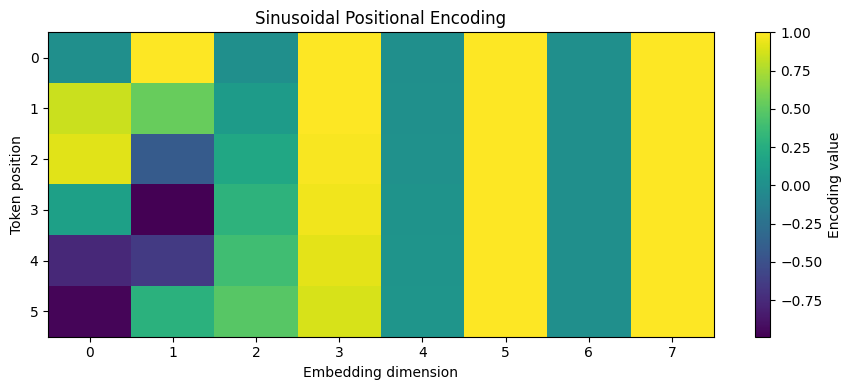

In [3]:
plt.figure(figsize=(9, 4))
plt.imshow(pos_encoder.pe[0, :seq_len].cpu().numpy(), aspect="auto", cmap="viridis")
plt.colorbar(label="Encoding value")
plt.xlabel("Embedding dimension")
plt.ylabel("Token position")
plt.title("Sinusoidal Positional Encoding")
plt.tight_layout()
plt.show()

## 4. Apply layer normalization

Layer normalization normalizes the features of each token independently. Given a token feature vector \(x\), it computes its mean \(\mu\) and variance \(\sigma^2\), then applies learnable scale and bias parameters:

\[
\operatorname{LayerNorm}(x)=\gamma\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta
\]

In PyTorch, `nn.LayerNorm(d_model)` normalizes the last dimension, which is the feature dimension in a tensor shaped `(batch, sequence length, d_model)`.

In [4]:
layer_norm = nn.LayerNorm(d_model)
normalized_embeddings = layer_norm(embeddings_with_position)

print("Before layer normalization (first token):")
print(embeddings_with_position[0, 0].round(decimals=4))
print("\nAfter layer normalization (first token):")
print(normalized_embeddings[0, 0].round(decimals=4))
print("\nMean of each normalized token:")
print(normalized_embeddings.mean(dim=-1).round(decimals=6))
print("\nVariance of each normalized token (population variance):")
print(normalized_embeddings.var(dim=-1, unbiased=False).round(decimals=6))

Before layer normalization (first token):
tensor([ 1.9269,  2.4873,  0.9007, -1.1055,  0.6784, -0.2345, -0.0431, -0.6047])

After layer normalization (first token):
tensor([ 1.2269,  1.7090,  0.3441, -1.3817,  0.1529, -0.6325, -0.4678, -0.9509],
       grad_fn=<RoundBackward1>)

Mean of each normalized token:
tensor([[0., -0., -0., -0., -0., 0.]], grad_fn=<RoundBackward1>)

Variance of each normalized token (population variance):
tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]],
       grad_fn=<RoundBackward1>)


## 5. Compare values before and after normalization
The plot compares one token's feature values before and after layer normalization. After normalization, features have approximately zero mean and unit population variance.

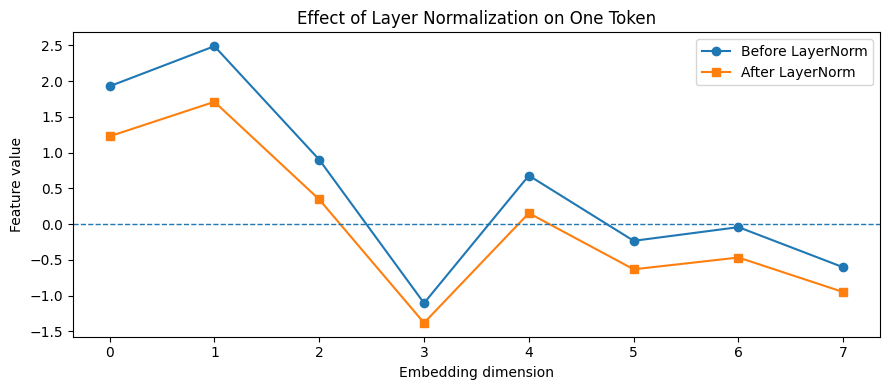

In [5]:
token_index = 0
before = embeddings_with_position[0, token_index].detach().cpu().numpy()
after = normalized_embeddings[0, token_index].detach().cpu().numpy()

feature_indices = list(range(d_model))
plt.figure(figsize=(9, 4))
plt.plot(feature_indices, before, marker="o", label="Before LayerNorm")
plt.plot(feature_indices, after, marker="s", label="After LayerNorm")
plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Embedding dimension")
plt.ylabel("Feature value")
plt.title("Effect of Layer Normalization on One Token")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Combine both operations in a Transformer-style input block
The simple input-preparation sequence is:

1. Convert tokens to embeddings.
2. Add positional encoding.
3. Apply layer normalization.

This is an illustrative input pipeline, not a complete Transformer encoder layer. A full encoder layer also includes self-attention, a feed-forward network, residual connections, and typically dropout.

In [6]:
class TransformerInputEmbedding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()
        self.positional_encoding = PositionalEncoding(d_model, max_len)
        self.layer_norm = nn.LayerNorm(d_model)

    def forward(self, token_embeddings: torch.Tensor) -> torch.Tensor:
        x = self.positional_encoding(token_embeddings)
        return self.layer_norm(x)


input_block = TransformerInputEmbedding(d_model=d_model, max_len=100)
output = input_block(embeddings)
print("Input shape: ", tuple(embeddings.shape))
print("Output shape:", tuple(output.shape))
print("All output values are finite:", bool(torch.isfinite(output).all()))

Input shape:  (1, 6, 8)
Output shape: (1, 6, 8)
All output values are finite: True


## Result
- Sinusoidal positional encoding was implemented and added to token embeddings.
- Layer normalization was applied along the embedding dimension for each token.
- The output tensor preserved the shape `(batch_size, sequence_length, d_model)`.
- The visualizations show position-dependent encoding values and the effect of normalization.

## Conclusion
Positional encoding supplies sequence-order information, while layer normalization stabilizes the scale of token features. Both are useful components in Transformer architectures.